<a href="https://colab.research.google.com/github/AnastasyaIrsyad/ProbStat_kel02/blob/main/Kode_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# 0. IMPORT LIBRARY
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_style('whitegrid')


In [ ]:
# ============================================================
# 1. MEMBACA DATA
# ============================================================
FILE = '3TIF_02_UlasanAplikasiPlayStore.xlsx'
df = pd.read_excel(FILE, sheet_name='Data')
print(df.head())


                            rev_app_id  Main_Category_UniqueVal  \
0  com.gameloft.android.ANMP.GloftPOHM                        0   
1  com.gameloft.android.ANMP.GloftPOHM                        0   
2  com.gameloft.android.ANMP.GloftPOHM                        0   
3  com.gameloft.android.ANMP.GloftPOHM                        0   
4  com.gameloft.android.ANMP.GloftPOHM                        0   

                            CleanedStop_review_body1  current_rating  \
0  muchas compras en aplicacin popups adems de mu...               3   
1  amazing gamelove offer buying pony gem really ...               4   
2  grrrr i happy game really fun got level 45 som...               3   
3  how am u supposed to save all equestria if i c...               5   
4  i love game much really fun amazing youtuber u...               5   

   required_android_version  TotNumRev  Installs  TotalAverageRating  
0                    4.0000    1347634  50000000              4.4000  
1                    4

In [ ]:
# ============================================================
# 2. IDENTIFIKASI DATA
# ============================================================
print('\n=== Ukuran data (baris, kolom) ===')
print(df.shape)

print('\n=== Tipe data tiap variabel ===')
print(df.dtypes)

print('\n=== Missing value tiap variabel ===')
print(df.isna().sum())

print('\n=== Jumlah baris duplikat ===')
print(df.duplicated().sum())

print('\n=== Jumlah nilai unik tiap variabel (cek variasi data) ===')
print(df.nunique())

print('\n=== Jumlah aplikasi unik ===')
print(df['rev_app_id'].nunique())

print('\n=== Jumlah ulasan per aplikasi ===')
print(df.groupby('rev_app_id').size().describe())

print('\n=== Distribusi rating per ulasan (current_rating) ===')
print(df['current_rating'].value_counts().sort_index())



=== Ukuran data (baris, kolom) ===
(60138, 8)

=== Tipe data tiap variabel ===
rev_app_id                   object
Main_Category_UniqueVal       int64
CleanedStop_review_body1     object
current_rating                int64
required_android_version    float64
TotNumRev                     int64
Installs                      int64
TotalAverageRating          float64
dtype: object

=== Missing value tiap variabel ===
rev_app_id                  0
Main_Category_UniqueVal     0
CleanedStop_review_body1    0
current_rating              0
required_android_version    0
TotNumRev                   0
Installs                    0
TotalAverageRating          0
dtype: int64

=== Jumlah baris duplikat ===
0

=== Jumlah nilai unik tiap variabel (cek variasi data) ===
rev_app_id                   3167
Main_Category_UniqueVal        14
CleanedStop_review_body1    47079
current_rating                  5
required_android_version       17
TotNumRev                    3095
Installs                       

In [ ]:

# ============================================================
# 3. MENYIAPKAN DATA PER APLIKASI (UNIT ANALISIS)
#    Variabel aplikasi bernilai sama di setiap ulasan aplikasi
#    yang sama, jadi diambil 1 baris per aplikasi.
# ============================================================
cek = df.groupby('rev_app_id')[['TotNumRev', 'Installs', 'TotalAverageRating',
                               'required_android_version']].nunique().max()
print('\n=== Cek konsistensi nilai per aplikasi (harus 1 semua) ===')
print(cek)

apps = (df.drop_duplicates(subset='rev_app_id')
          [['rev_app_id', 'Main_Category_UniqueVal', 'required_android_version',
            'TotNumRev', 'Installs', 'TotalAverageRating']]
          .reset_index(drop=True))
print('\nJumlah aplikasi yang dianalisis:', len(apps))

var_utama = ['TotalAverageRating', 'TotNumRev', 'Installs']



=== Cek konsistensi nilai per aplikasi (harus 1 semua) ===
TotNumRev                   1
Installs                    1
TotalAverageRating          1
required_android_version    1
dtype: int64

Jumlah aplikasi yang dianalisis: 3167



=== Statistika Deskriptif Variabel Utama ===
          TotalAverageRating          TotNumRev             Installs
count              3167.0000          3167.0000            3167.0000
mean                  4.2997        182656.1860         6187239.0275
std                   0.4028       1125381.4157        29505575.6089
min                   1.4000           478.0000            1000.0000
25%                   4.2000          6851.0000          500000.0000
50%                   4.4000         23593.0000         1000000.0000
75%                   4.6000         86675.5000         5000000.0000
max                   5.0000      48160293.0000      1000000000.0000
median                4.4000         23593.0000         1000000.0000
modus                 4.5000          3235.0000         1000000.0000
range                 3.6000      48159815.0000       999999000.0000
IQR                   0.4000         79824.5000         4500000.0000
varians               0.1622 1266483330707.4182 870578992

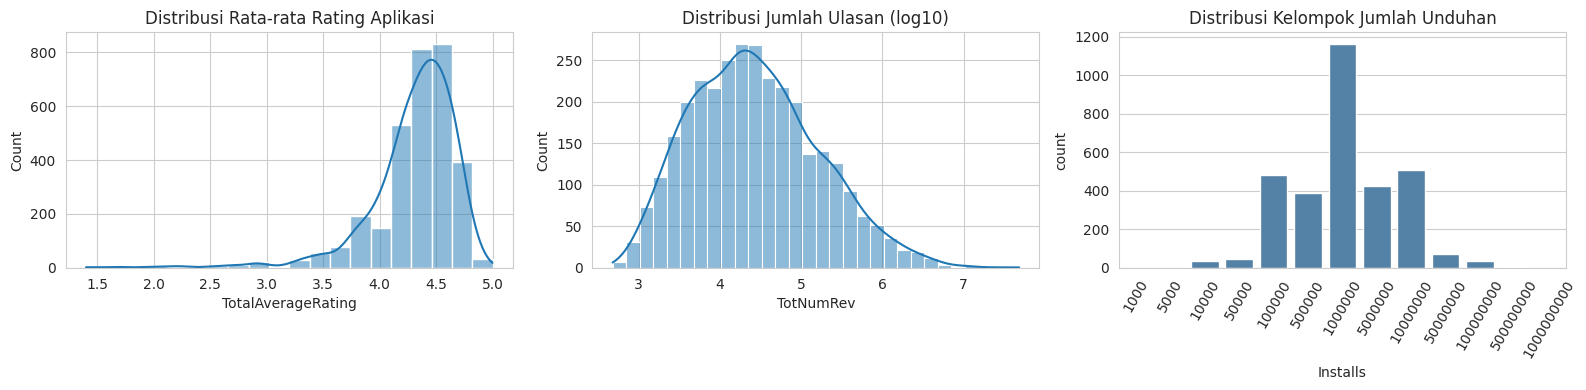

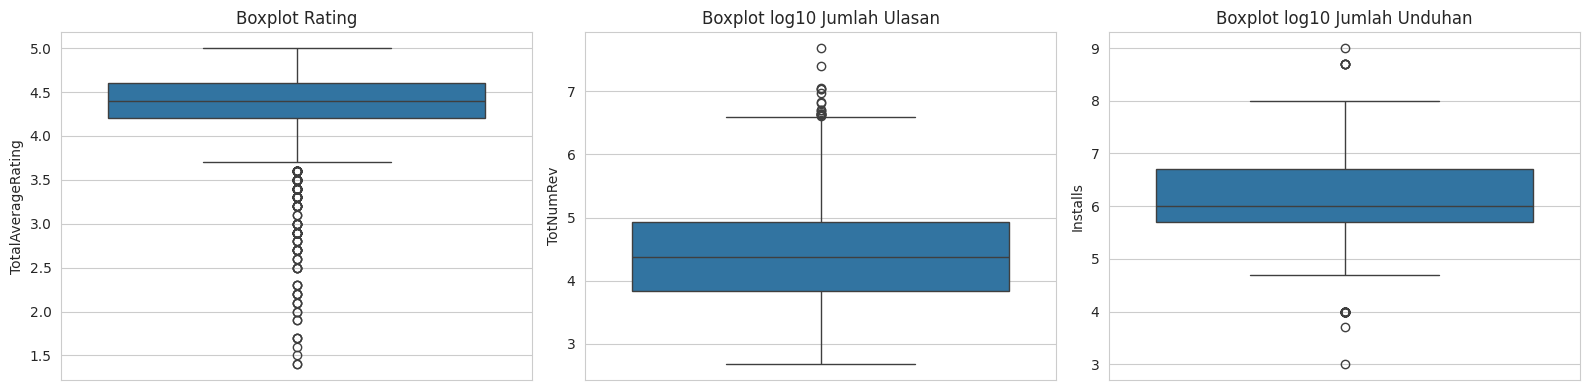

In [ ]:

# ============================================================
# 4. STATISTIKA DESKRIPTIF  (Rumusan Masalah 1)
# ============================================================
desk = apps[var_utama].describe().T
desk['median'] = apps[var_utama].median()
desk['modus'] = apps[var_utama].mode().iloc[0]
desk['range'] = desk['max'] - desk['min']
desk['IQR'] = desk['75%'] - desk['25%']
desk['varians'] = apps[var_utama].var()
desk['skewness'] = apps[var_utama].skew()
desk['kurtosis'] = apps[var_utama].kurt()
print('\n=== Statistika Deskriptif Variabel Utama ===')
print(desk.T)

print('\n=== Distribusi kelompok Installs ===')
print(apps['Installs'].value_counts().sort_index())

# Outlier dengan metode IQR
print('\n=== Jumlah outlier (metode IQR) ===')
for col in var_utama:
    q1, q3 = apps[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((apps[col] < q1 - 1.5 * iqr) | (apps[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: {n_out} outlier')

# Visualisasi: histogram
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(apps['TotalAverageRating'], bins=20, kde=True, ax=ax[0])
ax[0].set_title('Distribusi Rata-rata Rating Aplikasi')
sns.histplot(np.log10(apps['TotNumRev']), bins=30, kde=True, ax=ax[1])
ax[1].set_title('Distribusi Jumlah Ulasan (log10)')
sns.countplot(x=apps['Installs'], ax=ax[2], color='steelblue')
ax[2].set_title('Distribusi Kelompok Jumlah Unduhan')
ax[2].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()

# Visualisasi: boxplot
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(y=apps['TotalAverageRating'], ax=ax[0]); ax[0].set_title('Boxplot Rating')
sns.boxplot(y=np.log10(apps['TotNumRev']), ax=ax[1]); ax[1].set_title('Boxplot log10 Jumlah Ulasan')
sns.boxplot(y=np.log10(apps['Installs']), ax=ax[2]); ax[2].set_title('Boxplot log10 Jumlah Unduhan')
plt.tight_layout(); plt.show()




=== Uji Normalitas Kolmogorov-Smirnov (n besar) ===
TotalAverageRating: KS = 0.1578, p-value = 2.2146e-69 -> Tidak normal
TotNumRev: KS = 0.4357, p-value = 0.0000e+00 -> Tidak normal
Installs: KS = 0.4170, p-value = 0.0000e+00 -> Tidak normal


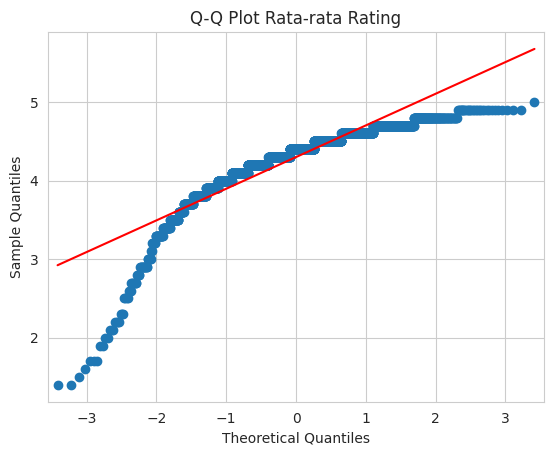

In [ ]:

# ============================================================
# 5. UJI NORMALITAS
# ============================================================
print('\n=== Uji Normalitas Kolmogorov-Smirnov (n besar) ===')
for col in var_utama:
    x = apps[col]
    stat, p = stats.kstest((x - x.mean()) / x.std(), 'norm')
    print(f'{col}: KS = {stat:.4f}, p-value = {p:.4e} ->',
          'Normal' if p > 0.05 else 'Tidak normal')

# Q-Q plot rating
sm.qqplot(apps['TotalAverageRating'], line='s')
plt.title('Q-Q Plot Rata-rata Rating'); plt.show()




=== Statistik rating per grup ===
                count   mean  median    std
grup_android                               
Android < 5.0    2848 4.3120  4.4000 0.3836
Android >= 5.0    319 4.1897  4.3000 0.5333
Normalitas Android >= 5.0: p-value = 2.4138e-10
Normalitas Android < 5.0: p-value = 3.5438e-56
Uji Levene: stat = 27.5269, p-value = 1.6513e-07

Uji Mann-Whitney U: U = 404503.50, p-value = 0.0012
Kesimpulan: Tolak H0 -> ada perbedaan rating yang signifikan
Pembanding Welch t-test: t = -3.9848, p-value = 0.0001


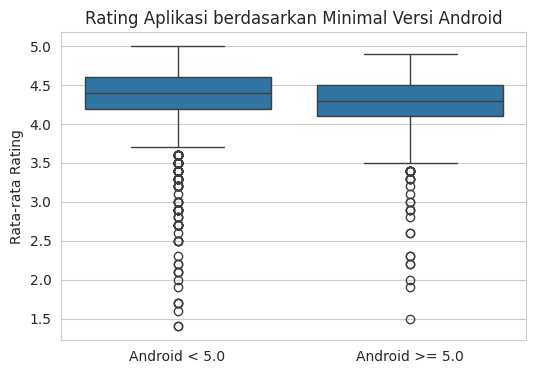

In [ ]:
# ============================================================
# 6. UJI BEDA  (Rumusan Masalah 2)
#    Rating aplikasi minimal Android >= 5.0 vs < 5.0
# ============================================================
apps['grup_android'] = np.where(apps['required_android_version'] >= 5.0,
                                'Android >= 5.0', 'Android < 5.0')
g_baru = apps.loc[apps['grup_android'] == 'Android >= 5.0', 'TotalAverageRating']
g_lama = apps.loc[apps['grup_android'] == 'Android < 5.0', 'TotalAverageRating']

print('\n=== Statistik rating per grup ===')
print(apps.groupby('grup_android')['TotalAverageRating']
          .agg(['count', 'mean', 'median', 'std']))

# Normalitas per grup
for nama, g in [('Android >= 5.0', g_baru), ('Android < 5.0', g_lama)]:
    s, p = stats.kstest((g - g.mean()) / g.std(), 'norm')
    print(f'Normalitas {nama}: p-value = {p:.4e}')

# Homogenitas varians
lev_stat, lev_p = stats.levene(g_baru, g_lama)
print(f'Uji Levene: stat = {lev_stat:.4f}, p-value = {lev_p:.4e}')

# H0: tidak ada perbedaan rating antara kedua grup
# H1: ada perbedaan rating antara kedua grup
u_stat, u_p = stats.mannwhitneyu(g_baru, g_lama, alternative='two-sided')
print(f'\nUji Mann-Whitney U: U = {u_stat:.2f}, p-value = {u_p:.4f}')
print('Kesimpulan:', 'Tolak H0 -> ada perbedaan rating yang signifikan'
      if u_p < 0.05 else 'Gagal tolak H0 -> tidak ada perbedaan signifikan')

# Pembanding: Welch t-test (tidak mengasumsikan varians sama)
t_stat, t_p = stats.ttest_ind(g_baru, g_lama, equal_var=False)
print(f'Pembanding Welch t-test: t = {t_stat:.4f}, p-value = {t_p:.4f}')

plt.figure(figsize=(6, 4))
sns.boxplot(data=apps, x='grup_android', y='TotalAverageRating')
plt.title('Rating Aplikasi berdasarkan Minimal Versi Android')
plt.xlabel(''); plt.ylabel('Rata-rata Rating'); plt.show()




=== Korelasi Spearman ===
                    TotalAverageRating  TotNumRev  Installs
TotalAverageRating              1.0000     0.1741   -0.0615
TotNumRev                       0.1741     1.0000    0.8373
Installs                       -0.0615     0.8373    1.0000
Rating vs TotNumRev: r = 0.1741, p-value = 5.7423e-23
Rating vs Installs: r = -0.0615, p-value = 5.3978e-04


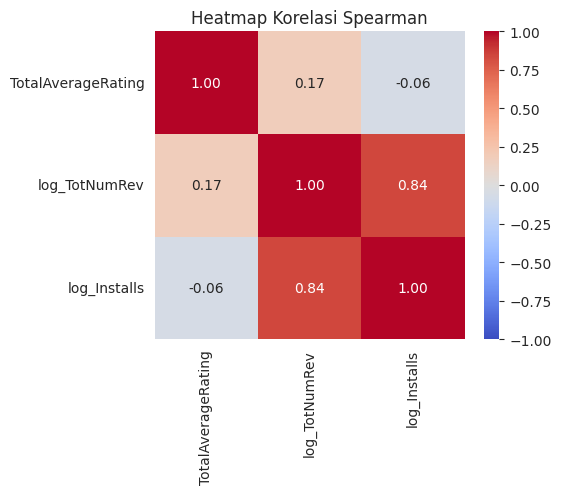

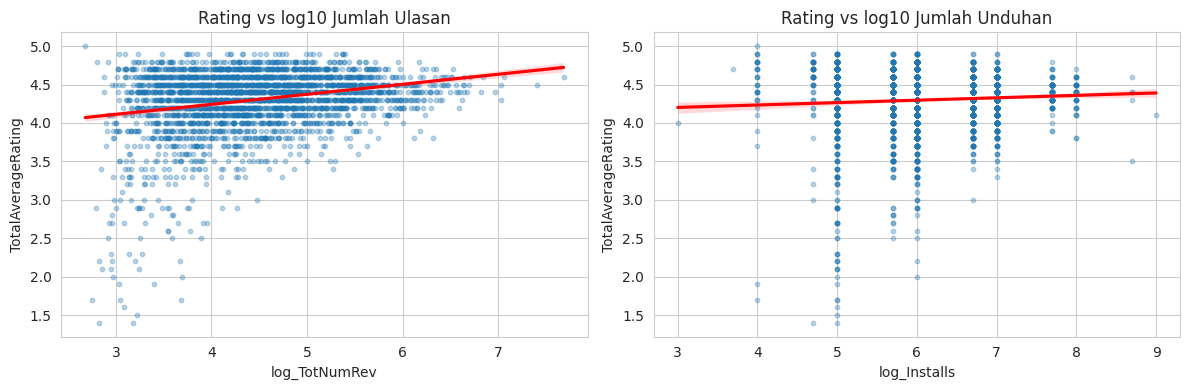

                            OLS Regression Results                            
Dep. Variable:     TotalAverageRating   R-squared:                       0.144
Model:                            OLS   Adj. R-squared:                  0.144
Method:                 Least Squares   F-statistic:                     266.4
Date:                Sun, 04 Oct 2026   Prob (F-statistic):          1.15e-107
Time:                        09:02:03   Log-Likelihood:                -1366.8
No. Observations:                3167   AIC:                             2740.
Df Residuals:                    3164   BIC:                             2758.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             4.3990      0.055     80.260

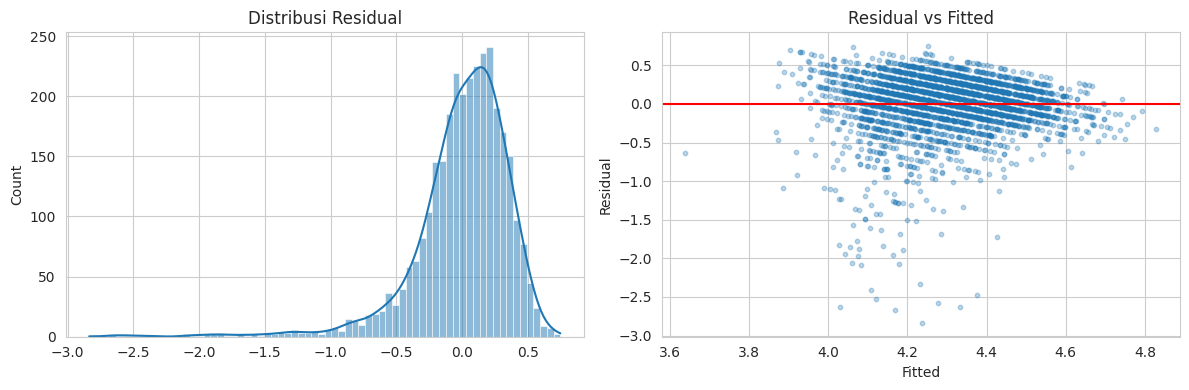

In [ ]:
# ============================================================
# 7. KORELASI & REGRESI  (Rumusan Masalah 3)
#    Jumlah ulasan & unduhan sangat menceng -> transformasi log10
# ============================================================
apps['log_TotNumRev'] = np.log10(apps['TotNumRev'])
apps['log_Installs'] = np.log10(apps['Installs'])

print('\n=== Korelasi Spearman ===')
print(apps[['TotalAverageRating', 'TotNumRev', 'Installs']].corr(method='spearman'))

for col in ['TotNumRev', 'Installs']:
    r, p = stats.spearmanr(apps['TotalAverageRating'], apps[col])
    print(f'Rating vs {col}: r = {r:.4f}, p-value = {p:.4e}')

plt.figure(figsize=(5, 4))
sns.heatmap(apps[['TotalAverageRating', 'log_TotNumRev', 'log_Installs']]
            .corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Spearman'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=apps, x='log_TotNumRev', y='TotalAverageRating', ax=ax[0],
            scatter_kws={'alpha': 0.3, 's': 10}, line_kws={'color': 'red'})
ax[0].set_title('Rating vs log10 Jumlah Ulasan')
sns.regplot(data=apps, x='log_Installs', y='TotalAverageRating', ax=ax[1],
            scatter_kws={'alpha': 0.3, 's': 10}, line_kws={'color': 'red'})
ax[1].set_title('Rating vs log10 Jumlah Unduhan')
plt.tight_layout(); plt.show()

# Regresi linear berganda
X = sm.add_constant(apps[['log_TotNumRev', 'log_Installs']])
y = apps['TotalAverageRating']
model = sm.OLS(y, X).fit()
print(model.summary())

# Multikolinearitas (VIF < 10 aman)
vif = pd.DataFrame({
    'Variabel': X.columns[1:],
    'VIF': [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]
})
print('\n=== VIF ===')
print(vif)

# Ringkasan hasil regresi
b = model.params
print(f'\nPersamaan: Rating = {b["const"]:.4f} + {b["log_TotNumRev"]:.4f}*log10(TotNumRev) '
      f'+ {b["log_Installs"]:.4f}*log10(Installs)')
print(f'R-squared = {model.rsquared:.4f} ({model.rsquared*100:.2f}% variasi rating dijelaskan model)')
print(f'Uji F: p-value = {model.f_pvalue:.4e}')
for v in ['log_TotNumRev', 'log_Installs']:
    print(f'Uji t {v}: p-value = {model.pvalues[v]:.4e} ->',
          'signifikan' if model.pvalues[v] < 0.05 else 'tidak signifikan')


# Uji asumsi residual
resid = model.resid
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(resid, kde=True, ax=ax[0]); ax[0].set_title('Distribusi Residual')
ax[1].scatter(model.fittedvalues, resid, alpha=0.3, s=10)
ax[1].axhline(0, color='red'); ax[1].set_title('Residual vs Fitted')
ax[1].set_xlabel('Fitted'); ax[1].set_ylabel('Residual')
plt.tight_layout(); plt.show()